In [6]:
from classy import Class
import numpy as np
import matplotlib.pyplot as plt

# Read CLASS input settings from the .ini.
params = {}
params.pop("overwrite_root", None)
with open("class_v3.4.0/my_test.ini") as f:
    for line in f:
        line = line.split("#", 1)[0].strip()  # remove comments
        if "=" in line:
            key, value = line.split("=", 1)
            if value.strip():                 # skip empty settings
                params[key.strip()] = value.strip()

# Set the parameters for this run.
params.update({
    "birefringence_A": 1.0,
    "birefringence_L": 0.000195, #1/1527 ish
    "output": "tCl,pCl",
    "l_max_scalars": "2500",
    "lensing": "no",
    "hierarchy": "tam",
    "root": "class_v3.4.0/output/alpha_sinc01_",
})
for key in (
    "lcmb_rescale", "lcmb_tilt", "lcmb_pivot",
    "P_k_max_h/Mpc", "z_pk", "overwrite_root",
):
    params.pop(key, None)

cosmo = Class()
cosmo.set(params)
cosmo.compute()

cls = cosmo.raw_cl(2500)  
np.savetxt(
    "eb_alpha_sinc.txt",  
    np.column_stack((cls["ell"], cls["eb"])),
    header="ell EB_unlensed",
)

Reading input parameters
 -> matched budget equations by adjusting Omega_Lambda = 0.690026
Running CLASS version v3.4.1
Computing background
 -> age = 13.770598 Gyr
 -> conformal age = 14151.897989 Mpc
 -> N_eff = 3.044 (summed over all species that are non-relativistic at early times) 
 -> radiation/matter equality at z = 3405.751108
    corresponding to conformal time = 112.722902 Mpc
Computing thermodynamics using HyRec 2020
 -> with primordial helium mass fraction Y_He = 0.2453
 -> recombination (maximum of visibility function) at z = 1088.772283
    corresponding to conformal time = 280.650572 Mpc
    with comoving sound horizon = 144.510391 Mpc
    angular diameter distance = 12.728574 Mpc
    sound horizon angle 100*theta_s = 1.041798
    Thomson optical depth crosses one at z_* = 1085.125754
    giving an angle 100*theta_* = 1.044146
 -> baryon drag stops at z = 1059.919234
    corresponding to conformal time = 286.316633 Mpc
    with comoving sound horizon rs = 147.071615 Mpc


In [20]:
from classy import Class
import numpy as np
import matplotlib.pyplot as plt

# Read CLASS input settings from the .ini.
params = {}
params.pop("overwrite_root", None)
with open("class_v3.4.0/my_test_b2zero.ini") as f:
    for line in f:
        line = line.split("#", 1)[0].strip()  # remove comments
        if "=" in line:
            key, value = line.split("=", 1)
            if value.strip():                 # skip empty settings
                params[key.strip()] = value.strip()

# Set the parameters for this run.
params.update({
    "birefringence_A": 1.0,
    "birefringence_L": 0.000195, #1/1527 ish
    "output": "tCl,pCl",
    "l_max_scalars": "2500",
    "lensing": "no",
    "hierarchy": "tam",
    "root": "class_v3.4.0/output/b2zero01_",
})
for key in (
    "lcmb_rescale", "lcmb_tilt", "lcmb_pivot",
    "P_k_max_h/Mpc", "z_pk", "overwrite_root",
):
    params.pop(key, None)

cosmo = Class()
cosmo.set(params)
cosmo.compute()

cls = cosmo.raw_cl(2500)  
np.savetxt(
    "tb_b2zero.txt",  
    np.column_stack((cls["ell"], cls["tb"])),
    header="ell TB_unlensed",
)

Reading input parameters
 -> matched budget equations by adjusting Omega_Lambda = 0.690026
Running CLASS version v3.4.1
Computing background
 -> age = 13.770598 Gyr
 -> conformal age = 14151.897989 Mpc
 -> N_eff = 3.044 (summed over all species that are non-relativistic at early times) 
 -> radiation/matter equality at z = 3405.751108
    corresponding to conformal time = 112.722902 Mpc
Computing thermodynamics using HyRec 2020
 -> with primordial helium mass fraction Y_He = 0.2453
 -> recombination (maximum of visibility function) at z = 1088.772283
    corresponding to conformal time = 280.650572 Mpc
    with comoving sound horizon = 144.510391 Mpc
    angular diameter distance = 12.728574 Mpc
    sound horizon angle 100*theta_s = 1.041798
    Thomson optical depth crosses one at z_* = 1085.125754
    giving an angle 100*theta_* = 1.044146
 -> baryon drag stops at z = 1059.919234
    corresponding to conformal time = 286.316633 Mpc
    with comoving sound horizon rs = 147.071615 Mpc


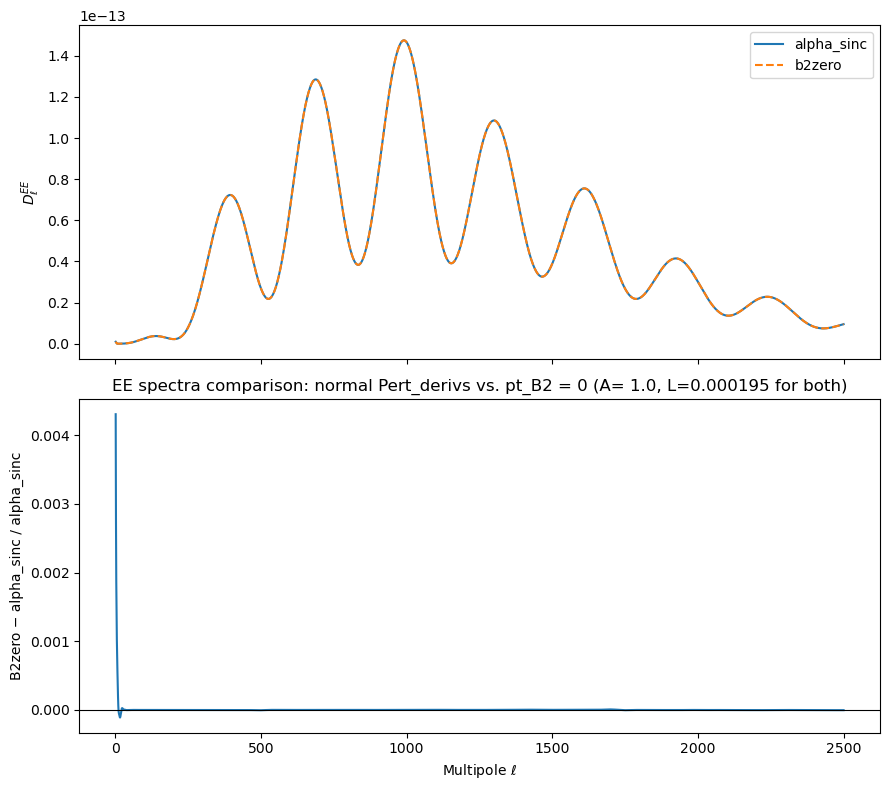

Maximum absolute difference in D_ell: 4.130731e-18
Maximum absolute percentage difference: 4.306411e-01 %


In [7]:
import numpy as np
import matplotlib.pyplot as plt
#.txt saved for difference pip install compilations of perturbations.c

##tt, te, tb, ee, eb, bb
sinc_ee = np.loadtxt("ee_alpha_sinc.txt", comments="#")
b2zero_ee = np.loadtxt("ee_b2zero.txt", comments="#")

sinc_tt = np.loadtxt("tt_alpha_sinc.txt", comments="#")
b2zero_tt = np.loadtxt("tt_b2zero.txt", comments="#")

sinc_te = np.loadtxt("te_alpha_sinc.txt", comments="#")
b2zero_te = np.loadtxt("te_b2zero.txt", comments="#")

sinc_tb = np.loadtxt("tb_alpha_sinc.txt", comments="#")
b2zero_tb = np.loadtxt("tb_b2zero.txt", comments="#")

sinc_eb = np.loadtxt("eb_alpha_sinc.txt", comments="#")
b2zero_eb = np.loadtxt("eb_b2zero.txt", comments="#")

sinc_bb = np.loadtxt("bb_alpha_sinc.txt", comments="#")
b2zero_bb = np.loadtxt("bb_b2zero.txt", comments="#")

ell = sinc_ee[:, 0]
ee_sinc = sinc_ee[:, 1]
ee_b2zero = b2zero_ee[:, 1]

tt_sinc = sinc_tt[:, 1]
tt_b2zero = b2zero_tt[:, 1]

te_sinc = sinc_te[:, 1]
te_b2zero = b2zero_te[:, 1]

tb_sinc = sinc_tb[:, 1]
tb_b2zero = b2zero_tb[:, 1]

eb_sinc = sinc_eb[:, 1]
eb_b2zero = b2zero_eb[:, 1]

bb_sinc = sinc_bb[:, 1]
bb_b2zero = b2zero_bb[:, 1]


#flag to make sure they are equivalent
if not np.array_equal(ell, b2zero_ee[:, 0]):
    raise ValueError("The files have different multipoles.")

# Compare only ell >= 2, where EE is defined and nonzero
mask = (ell >= 2) & (ee_sinc != 0)
ell = ell[mask]
ee_sinc = ee_sinc[mask]
ee_b2zero = ee_b2zero[mask]

tt_sinc = tt_sinc[mask]
tt_b2zero = tt_b2zero[mask]

te_sinc = te_sinc[mask]
te_b2zero = te_b2zero[mask]

tb_sinc = tb_sinc[mask]
tb_b2zero = tb_b2zero[mask]

eb_sinc = eb_sinc[mask]
eb_b2zero = eb_b2zero[mask]

bb_sinc = bb_sinc[mask]
bb_b2zero = bb_b2zero[mask]

# Convert C_ell to the D_ell convention used in CLASS output files
#fac = l(l+1)/(2pi)
factor = ell * (ell + 1) / (2 * np.pi)
dl_sinc_ee = factor * ee_sinc
dl_b2zero_ee = factor * ee_b2zero

dl_sinc_tt = factor * tt_sinc
dl_b2zero_tt = factor * tt_b2zero

dl_sinc_te = factor * te_sinc
dl_b2zero_te = factor * te_b2zero

dl_sinc_tb = factor * tb_sinc
dl_b2zero_tb = factor * tb_b2zero

dl_sinc_eb = factor * eb_sinc
dl_b2zero_eb = factor * eb_b2zero

dl_sinc_bb = factor * bb_sinc
dl_b2zero_bb = factor * bb_b2zero

#difference and $ difference
difference_ee = dl_b2zero_ee - dl_sinc_ee
residual_difference_ee = difference_ee / dl_sinc_ee

difference_tt = dl_b2zero_tt - dl_sinc_tt
residual_difference_tt = difference_tt / dl_sinc_tt

difference_te = dl_b2zero_te - dl_sinc_te
residual_difference_te = difference_te / dl_sinc_te

difference_tb = dl_b2zero_tb - dl_sinc_tb
residual_difference_tb = difference_tb / dl_sinc_tb

difference_eb = dl_b2zero_eb - dl_sinc_eb
residual_difference_eb = difference_eb / dl_sinc_eb

difference_bb = dl_b2zero_bb - dl_sinc_bb
residual_difference_bb = difference_bb / dl_sinc_bb

fig, (ax_spectra, ax_residual) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

plt.title("EE spectra comparison: normal Pert_derivs vs. pt_B2 = 0 (A= 1.0, L=0.000195 for both)")
ax_spectra.plot(ell, dl_sinc_ee, label="alpha_sinc")
ax_spectra.plot(ell, dl_b2zero_ee, "--", label="b2zero")
ax_spectra.set_ylabel(r"$D_\ell^{EE}$")
ax_spectra.legend()

ax_residual.plot(ell, residual_difference_ee)
ax_residual.axhline(0, color="black", linewidth=0.8)
ax_residual.set_xlabel(r"Multipole $\ell$")
ax_residual.set_ylabel("B2zero − alpha_sinc / alpha_sinc")


plt.tight_layout()
plt.show()

print(f"Maximum absolute difference in D_ell: {np.max(np.abs(difference_ee)):.6e}")
print(f"Maximum absolute percentage difference: {100*np.max(np.abs(residual_difference_ee)):.6e} %")

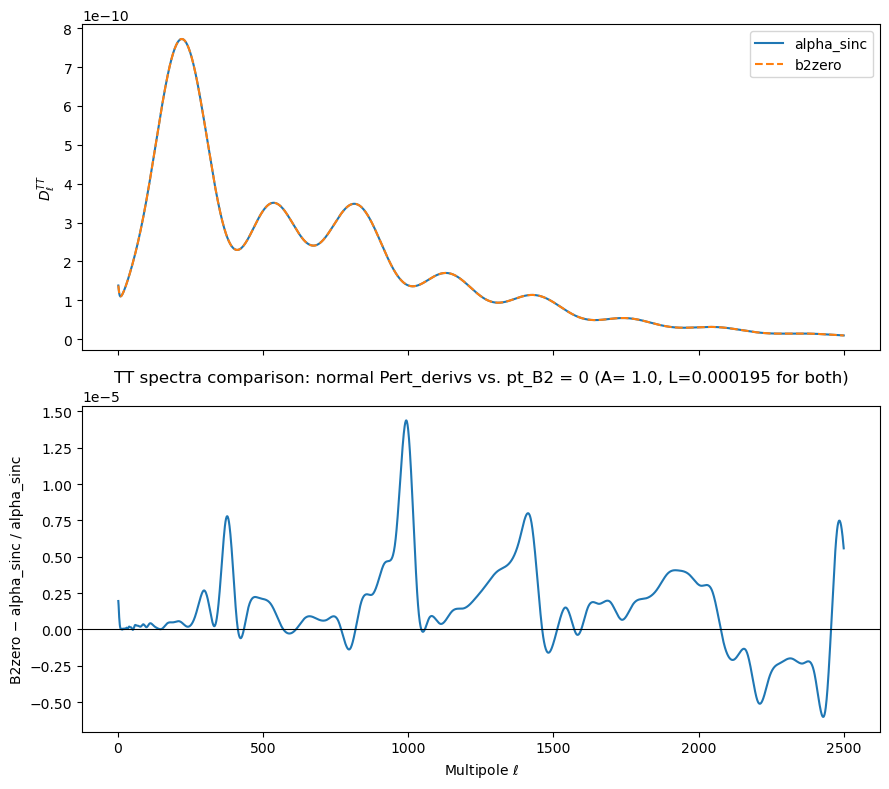

Maximum absolute difference in D_ell: 2.066050e-15
Maximum absolute percentage difference: 1.438101e-03 %


In [8]:

fig, (ax_spectra, ax_residual) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

plt.title("TT spectra comparison: normal Pert_derivs vs. pt_B2 = 0 (A= 1.0, L=0.000195 for both)")
ax_spectra.plot(ell, dl_sinc_tt, label="alpha_sinc")
ax_spectra.plot(ell, dl_b2zero_tt, "--", label="b2zero")
ax_spectra.set_ylabel(r"$D_\ell^{TT}$")
ax_spectra.legend()

ax_residual.plot(ell, residual_difference_tt)
ax_residual.axhline(0, color="black", linewidth=0.8)
ax_residual.set_xlabel(r"Multipole $\ell$")
ax_residual.set_ylabel("B2zero − alpha_sinc / alpha_sinc")


plt.tight_layout()
plt.show()

print(f"Maximum absolute difference in D_ell: {np.max(np.abs(difference_tt)):.6e}")
print(f"Maximum absolute percentage difference: {100*np.max(np.abs(residual_difference_tt)):.6e} %")

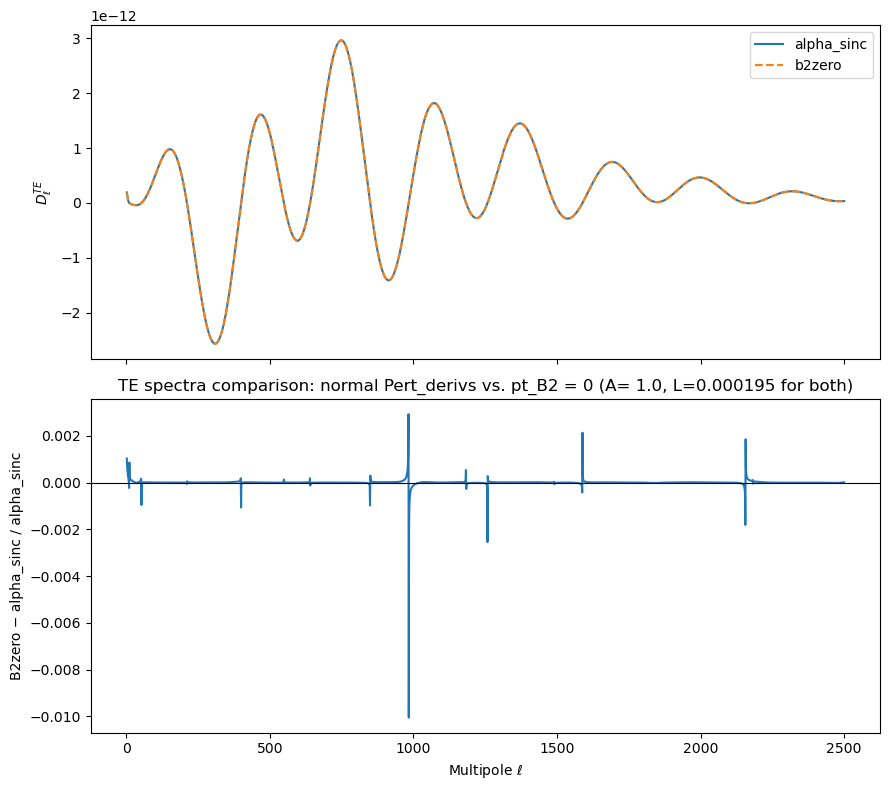

Maximum absolute difference in D_ell: 1.973156e-16
Maximum absolute percentage difference: 1.004586e+00 %


In [9]:

fig, (ax_spectra, ax_residual) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

plt.title("TE spectra comparison: normal Pert_derivs vs. pt_B2 = 0 (A= 1.0, L=0.000195 for both)")
ax_spectra.plot(ell, dl_sinc_te, label="alpha_sinc")
ax_spectra.plot(ell, dl_b2zero_te, "--", label="b2zero")
ax_spectra.set_ylabel(r"$D_\ell^{TE}$")
ax_spectra.legend()

ax_residual.plot(ell, residual_difference_te)
ax_residual.axhline(0, color="black", linewidth=0.8)
ax_residual.set_xlabel(r"Multipole $\ell$")
ax_residual.set_ylabel("B2zero − alpha_sinc / alpha_sinc")


plt.tight_layout()
plt.show()

print(f"Maximum absolute difference in D_ell: {np.max(np.abs(difference_te)):.6e}")
print(f"Maximum absolute percentage difference: {100*np.max(np.abs(residual_difference_te)):.6e} %")

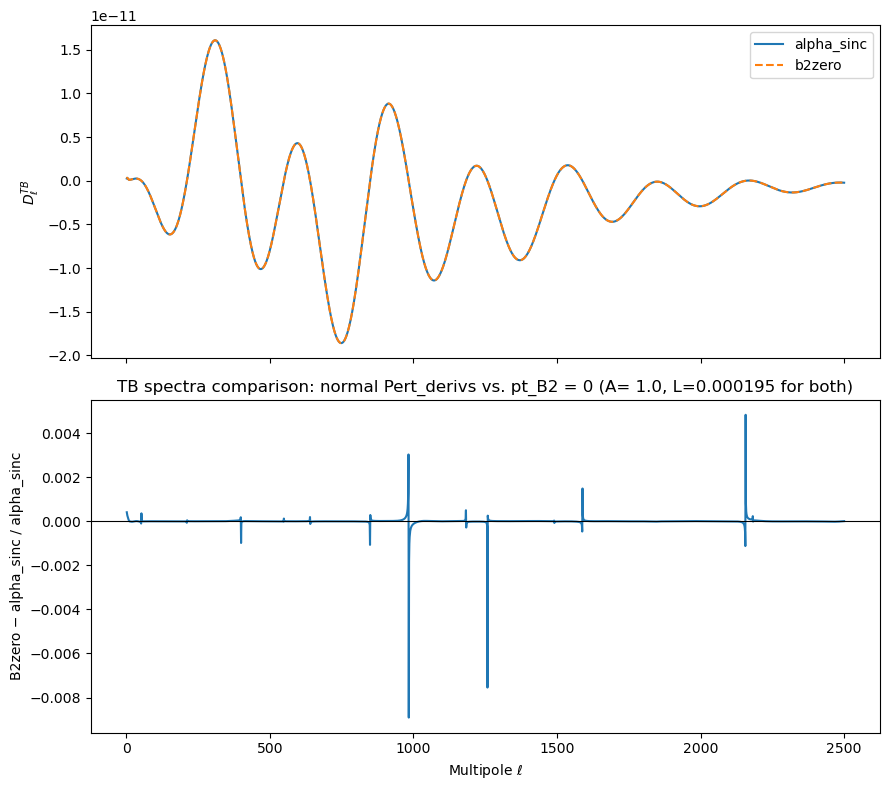

Maximum absolute difference in D_ell: 4.693436e-16
Maximum absolute percentage difference: 8.910543e-01 %


In [10]:

fig, (ax_spectra, ax_residual) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

plt.title("TB spectra comparison: normal Pert_derivs vs. pt_B2 = 0 (A= 1.0, L=0.000195 for both)")
ax_spectra.plot(ell, dl_sinc_tb, label="alpha_sinc")
ax_spectra.plot(ell, dl_b2zero_tb, "--", label="b2zero")
ax_spectra.set_ylabel(r"$D_\ell^{TB}$")
ax_spectra.legend()

ax_residual.plot(ell, residual_difference_tb)
ax_residual.axhline(0, color="black", linewidth=0.8)
ax_residual.set_xlabel(r"Multipole $\ell$")
ax_residual.set_ylabel("B2zero − alpha_sinc / alpha_sinc")


plt.tight_layout()
plt.show()

print(f"Maximum absolute difference in D_ell: {np.max(np.abs(difference_tb)):.6e}")
print(f"Maximum absolute percentage difference: {100*np.max(np.abs(residual_difference_tb)):.6e} %")

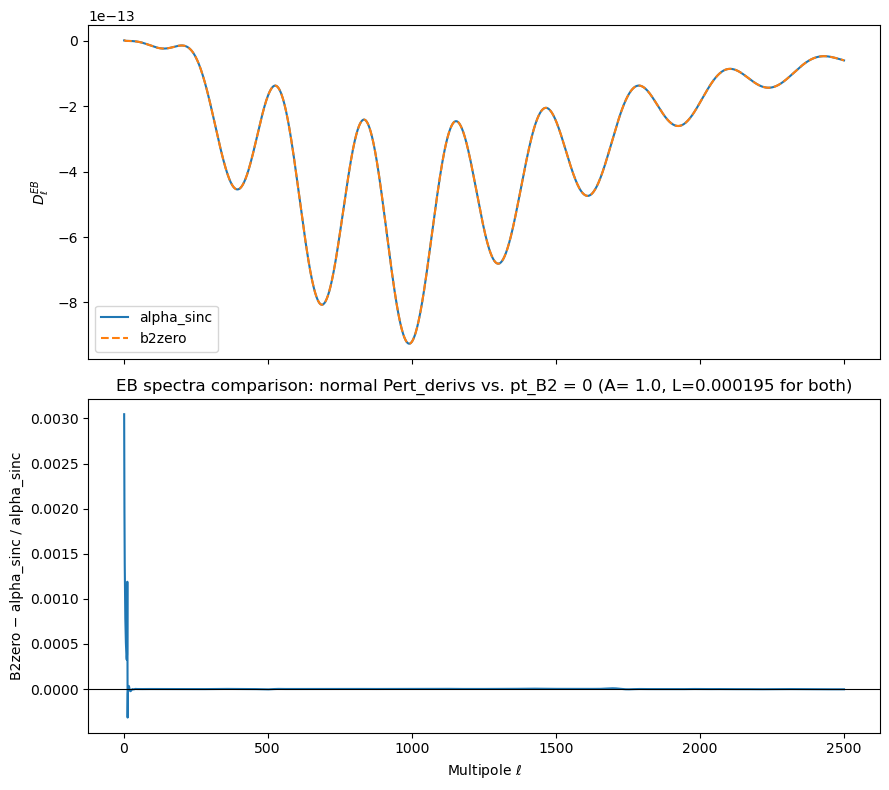

Maximum absolute difference in D_ell: 4.949053e-18
Maximum absolute percentage difference: 3.047283e-01 %


In [11]:

fig, (ax_spectra, ax_residual) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

plt.title("EB spectra comparison: normal Pert_derivs vs. pt_B2 = 0 (A= 1.0, L=0.000195 for both)")
ax_spectra.plot(ell, dl_sinc_eb, label="alpha_sinc")
ax_spectra.plot(ell, dl_b2zero_eb, "--", label="b2zero")
ax_spectra.set_ylabel(r"$D_\ell^{EB}$")
ax_spectra.legend()

ax_residual.plot(ell, residual_difference_eb)
ax_residual.axhline(0, color="black", linewidth=0.8)
ax_residual.set_xlabel(r"Multipole $\ell$")
ax_residual.set_ylabel("B2zero − alpha_sinc / alpha_sinc")


plt.tight_layout()
plt.show()

print(f"Maximum absolute difference in D_ell: {np.max(np.abs(difference_eb)):.6e}")
print(f"Maximum absolute percentage difference: {100*np.max(np.abs(residual_difference_eb)):.6e} %")

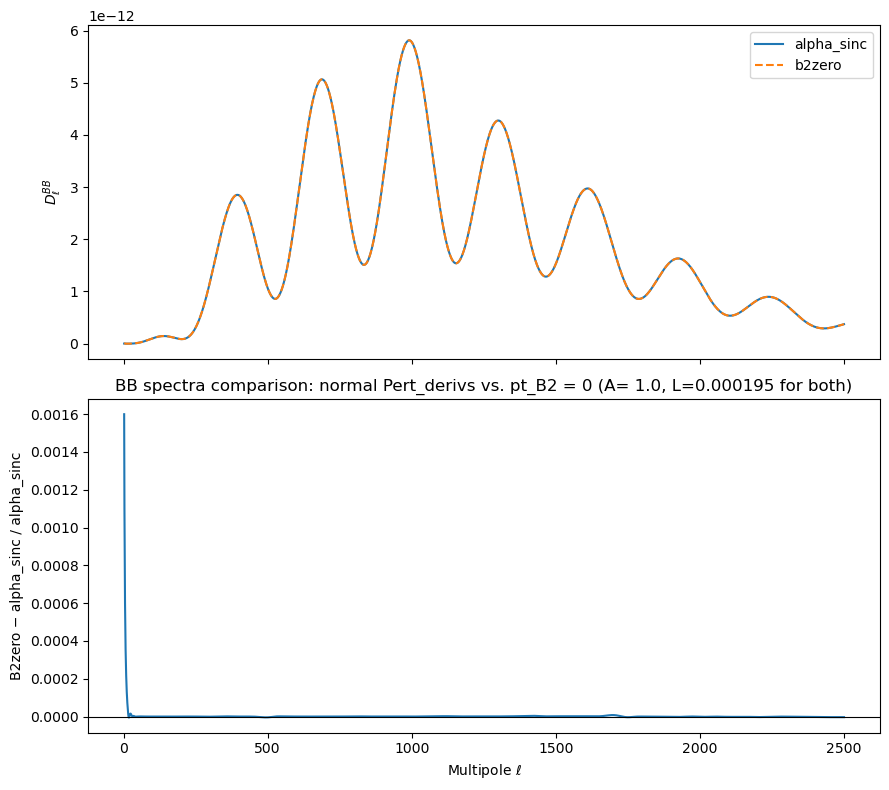

Maximum absolute difference in D_ell: 1.529766e-17
Maximum absolute percentage difference: 1.599882e-01 %


In [12]:

fig, (ax_spectra, ax_residual) = plt.subplots(
    2, 1, figsize=(9, 8), sharex=True
)

plt.title("BB spectra comparison: normal Pert_derivs vs. pt_B2 = 0 (A= 1.0, L=0.000195 for both)")
ax_spectra.plot(ell, dl_sinc_bb, label="alpha_sinc")
ax_spectra.plot(ell, dl_b2zero_bb, "--", label="b2zero")
ax_spectra.set_ylabel(r"$D_\ell^{BB}$")
ax_spectra.legend()

ax_residual.plot(ell, residual_difference_bb)
ax_residual.axhline(0, color="black", linewidth=0.8)
ax_residual.set_xlabel(r"Multipole $\ell$")
ax_residual.set_ylabel("B2zero − alpha_sinc / alpha_sinc")


plt.tight_layout()
plt.show()

print(f"Maximum absolute difference in D_ell: {np.max(np.abs(difference_bb)):.6e}")
print(f"Maximum absolute percentage difference: {100*np.max(np.abs(residual_difference_bb)):.6e} %")